In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
dataset_path = r"C:\Users\adhur\Downloads\DATA SCIENCE & GEN A I\DEEP LEARNING\CNN projetcs\project 3\datasets"

## Training Dataset

In [3]:
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(150,150),
    batch_size=32)

Found 6555 files belonging to 12 classes.
Using 5244 files for training.


## Validation Dataset

In [4]:
validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(150,150),
    batch_size=32
)

Found 6555 files belonging to 12 classes.
Using 1311 files for validation.


## Images Show

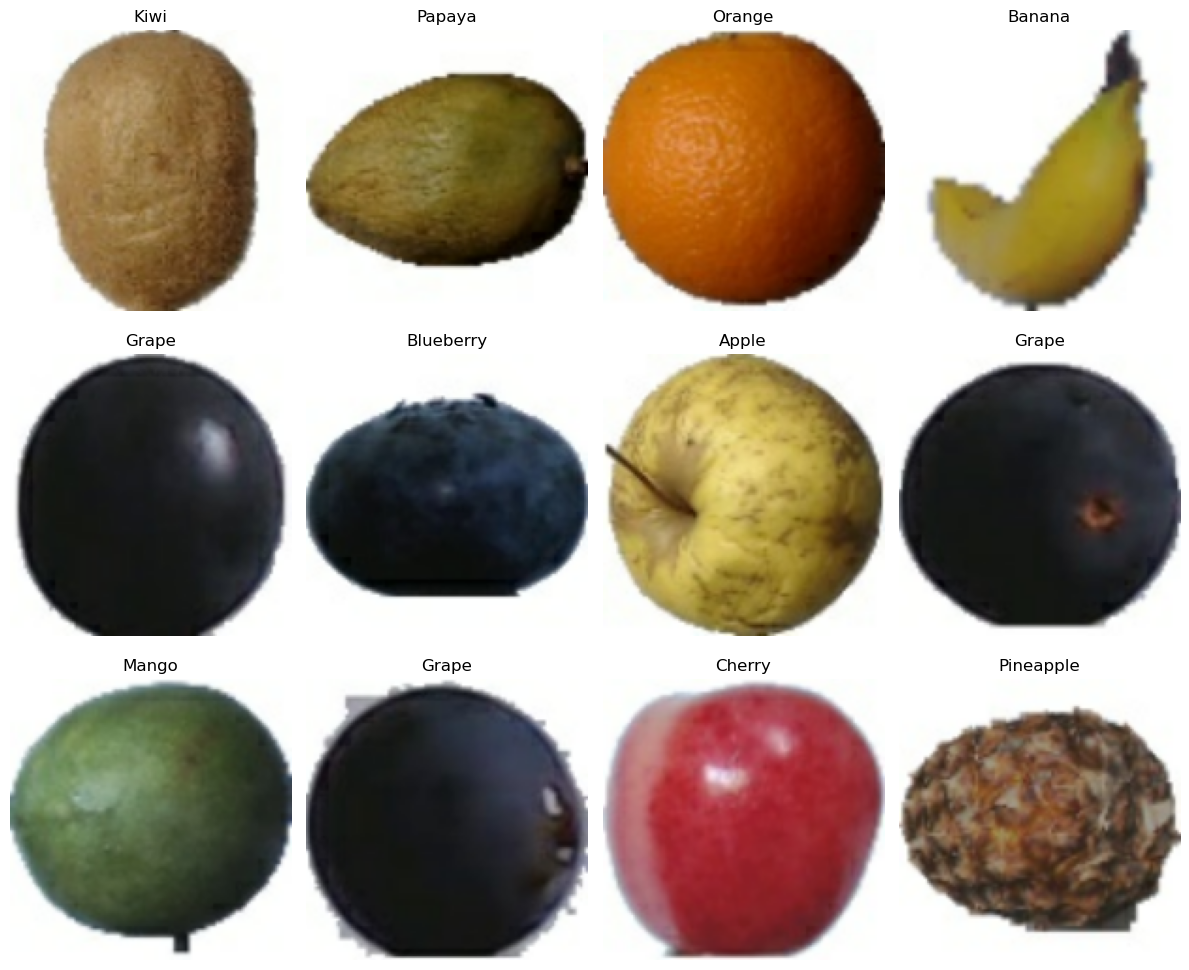

In [5]:
class_names = train_dataset.class_names

plt.figure(figsize=(12,10))

for images, labels in train_dataset.take(1):
    for i in range(12):
        plt.subplot(3,4,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

## Normalization

In [6]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

## BUILD CNN

Performance improve

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)

## CNN Model

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([
    
    Conv2D(32, (3,3), activation="relu", input_shape=(150,150,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(12, activation="softmax")
])

C:\Users\adhur\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36992)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,735,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 12)                  │           1,548 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,829,900 (18.42 MB)

 Trainable params: 4,829,900 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10


C:\Users\adhur\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


164/164 ━━━━━━━━━━━━━━━━━━━━ 41s 222ms/step - accuracy: 0.8555 - loss: 0.4313 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 39s 238ms/step - accuracy: 0.9870 - loss: 0.0352 - val_accuracy: 1.0000 - val_loss: 7.1963e-05
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 36s 220ms/step - accuracy: 0.9922 - loss: 0.0297 - val_accuracy: 1.0000 - val_loss: 4.3818e-04
Epoch 4/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 36s 217ms/step - accuracy: 0.9893 - loss: 0.0301 - val_accuracy: 1.0000 - val_loss: 4.4470e-05
Epoch 5/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 37s 227ms/step - accuracy: 0.9897 - loss: 0.0341 - val_accuracy: 1.0000 - val_loss: 6.9459e-04
Epoch 6/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 39s 239ms/step - accuracy: 0.9935 - loss: 0.0187 - val_accuracy: 1.0000 - val_loss: 1.8794e-04
Epoch 7/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 36s 221ms/step - accuracy: 0.9802 - loss: 0.0831 - val_accuracy: 0.9985 - val_loss: 0.0043
Epoch 8/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 36s 220ms/step - accuracy: 0.9933 

## Model Evaluate

In [12]:
loss, accuracy = model.evaluate(validation_dataset)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 1.0000 - loss: 1.4034e-05
Validation Loss: 1.4033692423254251e-05
Validation Accuracy: 1.0


## Accuracy Graph

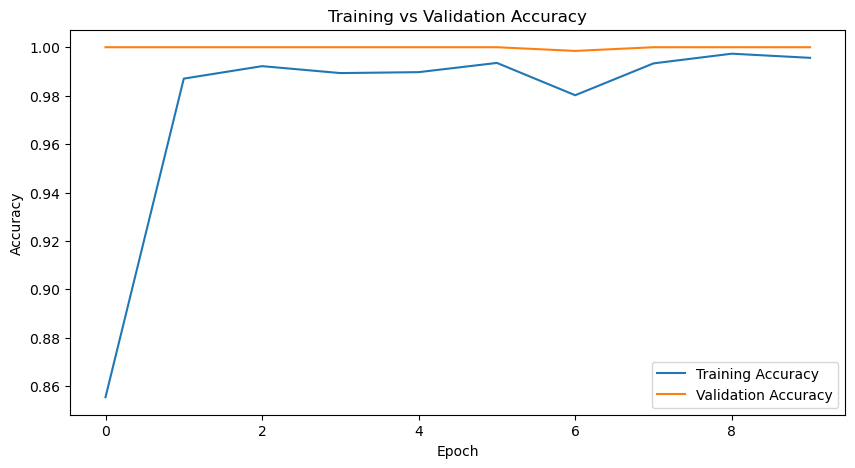

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

## Loss Graph

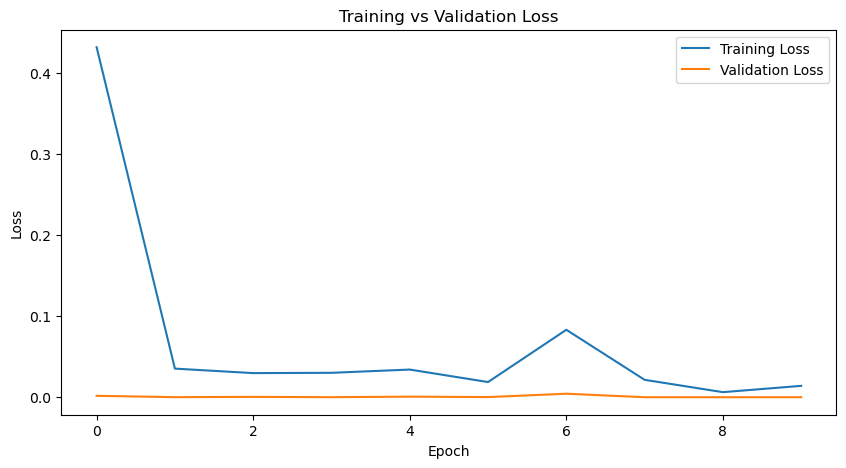

In [14]:
plt.figure(figsize=(10,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

##  save the model

In [15]:
model.save("fruit_classifier.keras")

## Predict a New Fruit Image

In [20]:
import numpy as np
from tensorflow.keras.preprocessing import image

img_path = "testing_images/apple.jpg"   # നിങ്ങളുടെ test image path

img = image.load_img(img_path, target_size=(150,150))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

prediction = model.predict(img_array)

class_names = [
    "Apple","Banana","Blueberry","Cherry",
    "Grape","Kiwi","Lemon","Mango",
    "Orange","Papaya","Pineapple","Strawberry"
]

predicted_class = class_names[np.argmax(prediction)]

print("Predicted Fruit:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
Predicted Fruit: Strawberry


In [18]:
prediction

array([[2.9165790e-16, 2.0064710e-10, 4.5811744e-19, 1.2311524e-15,
        1.5769529e-22, 1.9206086e-21, 1.0000000e+00, 7.0420391e-28,
        1.2121712e-12, 4.3165431e-17, 7.6860808e-20, 3.2486539e-17]],
      dtype=float32)